# Практическая работа № 4 — последовательное понижение степени полинома

**Исходные данные:** первые 60 наблюдений количества SSH brute-force инцидентов (шаг — 30 секунд, с 03.09.2026 10:26:30).  
**Методы:** канонический полином (система Вандермонда), полином Лагранжа, полином Ньютона, схема Эйткена.

## Важная математическая оговорка

- **60 различных узлов однозначно задают полином степени не выше 59**. Полином степени 60 по 60 узлам **не единственен**: можно прибавлять к полиному степени 59 произведение `C · ∏(t−tᵢ)` с произвольным `C`. Поэтому степень 60 в результатах помечается как неидентифицируемая, и честный перебор **начинается с 59**.
- В **точной интерполяции** полином степени `d` строится по `d+1` узлам. Мы **не подменяем** это регрессией по всем точкам. Степень уменьшается последовательно: `59, 58, ..., 1, 0`.
- Если оценивать ошибку на самих узлах, степень 59 даст ноль по определению. Для **поиска полезной степени** выделяем фиксированные скрытые наблюдения и считаем ошибки **по ним**. Они не участвуют в построении моделей степени `≤ 47`.
- Четыре метода при одинаковых узлах задают **один и тот же полином** и в точной арифметике имеют одинаковую точность. Их графики могут различаться только из-за численной погрешности.
- Для соответствия заданию также выполняем полный перебор степеней `29..0` на двух временных интервалах **1–30** и **31–60**. В отчёте можно выбрать три представительные степени в каждом интервале.

Ноутбук показывает *каждый шаг снижения степени*, графики, коэффициенты, сравнительные таблицы и автоматически находит лучшую степень по MAE на скрытых точках. Подходящий порог MAPE пользователь может поменять.

In [1]:
import importlib.util, subprocess, sys
for p in ('mpmath', 'numpy', 'pandas', 'matplotlib'):
    if importlib.util.find_spec(p) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', p])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mpmath as mp
from IPython.display import display
try:
    from ipywidgets import interact, IntSlider, Dropdown, Checkbox
    HAS_WIDGETS = True
except ImportError:
    HAS_WIDGETS = False
    print('ipywidgets не установлен: интерактивный просмотр заменён вызовом функции interactive_plot(...)')

mp.mp.dps = 90  # высокая точность важна для степени 59
pd.set_option('display.max_columns', 20)
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.grid'] = True
print('Среда готова; точность mpmath:', mp.mp.dps, 'знаков')

ipywidgets не установлен: интерактивный просмотр заменён вызовом функции interactive_plot(...)
Среда готова; точность mpmath: 90 знаков


60 точек; среднее 21.833, диапазон [16; 27]


,Наблюдение,Инцидентов / 30 с
0,1,21
1,2,18
2,3,21
3,4,18
4,5,18
5,6,22
6,7,16
7,8,27
8,9,26
9,10,22


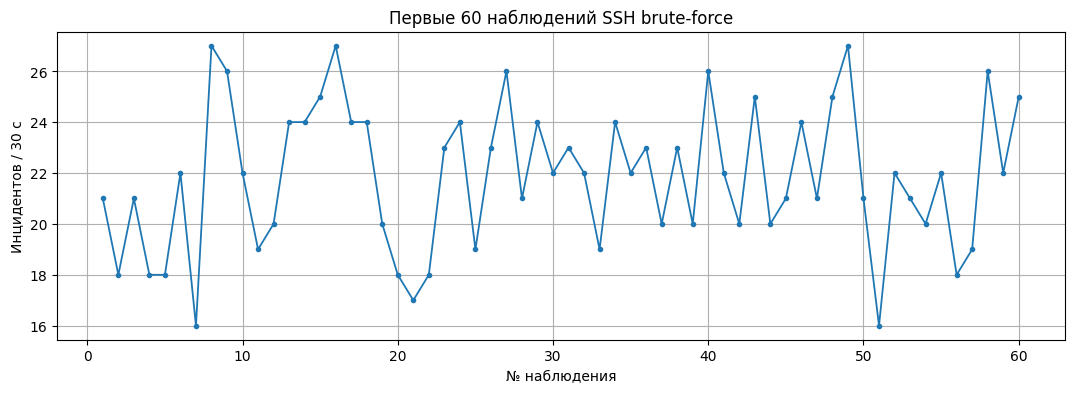

In [2]:
# Первые 60 реальных значений из таблицы «Ермакова 1».
Y = np.array([
    21,18,21,18,18,22,16,27,26,22,19,20,24,24,25,
    27,24,24,20,18,17,18,23,24,19,23,26,21,24,22,
    23,22,19,24,22,23,20,23,20,26,22,20,25,20,21,
    24,21,25,27,21,16,22,21,20,22,18,19,26,22,25
], dtype=float)
T = np.arange(1, len(Y) + 1, dtype=int)
assert len(Y) == 60
print(f'60 точек; среднее {np.mean(Y):.3f}, диапазон [{np.min(Y):.0f}; {np.max(Y):.0f}]')
display(pd.DataFrame({'Наблюдение':T, 'Инцидентов / 30 с':Y.astype(int)}).head(12))
plt.figure(figsize=(13,4))
plt.plot(T, Y, marker='o', markersize=3, linewidth=1.3)
plt.title('Первые 60 наблюдений SSH brute-force');plt.xlabel('№ наблюдения');plt.ylabel('Инцидентов / 30 с');plt.show()

## 1. Реализация четырёх **разных форм вычисления** интерполяционного полинома

Здесь `u = (t − центр) / масштаб` — линейная нормировка времени. Она уменьшает численные ошибки, не меняя степени и значения полинома.

- **Канонический:** `P(u) = a₀ + a₁u + ⋯ + aₙuⁿ`; коэффициенты из СЛАУ Вандермонда.
- **Лагранж:** базисные полиномы; для устойчивого вычисления применяется эквивалентная барицентрическая форма.
- **Ньютон:** форма с разделёнными разностями.
- **Эйткен:** рекуррентная интерполяционная схема Невилла–Эйткена.

При степени 0 полином является константой. Все четыре алгоритма поддерживают и этот случай.

In [3]:
METHODS = ('Канонический', 'Лагранж', 'Ньютон', 'Эйткен')

def choose_nodes(tpool, ypool, degree):
    """Ровно d+1 равномерно расположенных ВЫБРАННЫХ узлов для интерполяции."""
    if not 0 <= degree < len(tpool):
        raise ValueError('Для степени d требуется d+1 различных узлов')
    if degree == 0:
        ix = np.array([len(tpool)//2], dtype=int)
    else:
        ix = np.rint(np.linspace(0, len(tpool)-1, degree+1)).astype(int)
    assert len(np.unique(ix)) == degree+1
    return np.asarray(tpool)[ix], np.asarray(ypool)[ix]

def build_poly(xnodes, ynodes):
    """Один и тот же полином как 4 вычислительные формы."""
    xx = [mp.mpf(int(x)) for x in xnodes]
    yy = [mp.mpf(str(float(y))) for y in ynodes]
    n = len(xx)
    center = (xx[0]+xx[-1])/2
    scale = (xx[-1]-xx[0])/2 if n > 1 else mp.mpf(1)
    uu = [(x-center)/scale for x in xx]
    # Каноническая форма: V * a = y
    if n == 1:
        canonical = [yy[0]]
        ww = [mp.mpf(1)]
        divided = [yy[0]]
    else:
        V = mp.matrix([[u**j for j in range(n)] for u in uu])
        canonical = list(mp.lu_solve(V, mp.matrix(yy)))
        # Весовые коэффициенты Лагранжа
        ww = [1/mp.fprod(uu[i]-uu[j] for j in range(n) if j!=i) for i in range(n)]
        # Разделённые разности Ньютона
        dd = yy[:]
        divided = [dd[0]]
        for k in range(1, n):
            dd = [(dd[j+1]-dd[j])/(uu[j+k]-uu[j]) for j in range(n-k)]
            divided.append(dd[0])
    return {'x': xx, 'y': yy, 'u': uu, 'center': center, 'scale': scale,
            'canonical': canonical, 'weights': ww, 'newton': divided, 'degree': n-1}

def evaluate_one(p, t, method):
    u = (mp.mpf(str(float(t))) - p['center']) / p['scale']
    nodes, yy = p['u'], p['y']
    n = len(nodes)
    for j in range(n):
        if u == nodes[j]: return yy[j]
    if method == 'Канонический':
        v = mp.mpf(0)
        for a in reversed(p['canonical']): v = v*u+a
        return v
    if method == 'Лагранж':
        z = [p['weights'][j] / (u-nodes[j]) for j in range(n)]
        return mp.fsum(z[j]*yy[j] for j in range(n)) / mp.fsum(z)
    if method == 'Ньютон':
        v = p['newton'][-1]
        for j in range(n-2, -1, -1): v = v*(u-nodes[j])+p['newton'][j]
        return v
    if method == 'Эйткен':
        q = yy[:]
        for width in range(1,n):
            for i in range(n-width):
                j=i+width
                q[i] = ((u-nodes[i])*q[i+1] - (u-nodes[j])*q[i])/(nodes[j]-nodes[i])
        return q[0]
    raise ValueError(f'Неизвестный метод: {method}')

def evaluate(p, time_points, method):
    return np.array([float(evaluate_one(p, t, method)) for t in np.asarray(time_points)])

def calc_metrics(actual, forecast):
    a, f = np.asarray(actual,float), np.asarray(forecast,float)
    diff = a-f
    return dict(MAE=float(np.mean(abs(diff))), MSE=float(np.mean(diff**2)),
                RMSE=float(np.sqrt(np.mean(diff**2))), MAPE=float(np.mean(abs(diff)/np.maximum(abs(a),1e-12))*100))

def coeff_table(p):
    return pd.DataFrame({'Степень u': np.arange(p['degree']+1),
          'Канонический a_k': [mp.nstr(z, 13) for z in p['canonical']],
          'Ньютон: разделённая разность c_k': [mp.nstr(z, 13) for z in p['newton']]})

print('Проверка на двух узлах:')
pcheck=build_poly([1,5],[21,18])
print({m:mp.nstr(evaluate_one(pcheck,3.5,m),10) for m in METHODS})

Проверка на двух узлах:
{'Канонический': '19.125', 'Лагранж': '19.125', 'Ньютон': '19.125', 'Эйткен': '19.125'}


## 2. Полный перебор **каждой степени по порядку**

В таблице **60 → 0** степень 60 отображается как невозможная для однозначной интерполяции. Для остальных степеней перебор идёт **без пропусков**.

Для каждого интервала заранее резервируется около 20% точек для проверки (**одни и те же** для всех сравниваемых степеней). Поэтому:

- Степени `0..(число обучающих точек − 1)` оцениваются по независимым скрытым точкам.
- Более высокие степени можно построить только с использованием части/всех скрытых точек. Для них показывается **ошибка на наблюдениях**, но они **не участвуют** в выборе лучшего проверенного полинома.

**Критерий «максимально близко к нашим данным» = минимальная MAE на скрытых наблюдениях.** Также показывается первая степень при движении сверху вниз, достигшая заданного порога MAPE (по умолчанию 15%).

Это именно **интерполяция** по `d+1` выбранным узлам. Не путать с полиномиальной регрессией МНК по всем 60 наблюдениям.

In [4]:
INTERVALS = {'Все 60 (1–60)': (T, Y), 'Первый (1–30)': (T[:30],Y[:30]), 'Второй (31–60)': (T[30:],Y[30:])}
MAPE_TARGET = 15.0  # Пользовательский критерий, НЕ требование методички
SCAN = {}             # отдельные результаты для каждого интервала
MODELS = {}           # ключ (интервал, степень): полином и используемые узлы

for interval_name, (tx, yy) in INTERVALS.items():
    n = len(tx)
    test_mask = np.zeros(n, dtype=bool)
    test_mask[np.arange(3,n,5)] = True  # фиксированные скрытые 4,9,...; крайние точки остаются
    train_x, train_y = tx[~test_mask], yy[~test_mask]
    test_x, test_y = tx[test_mask], yy[test_mask]
    max_valid_degree = len(train_x)-1
    table = []

    for d in range(n-1, -1, -1):  # 59,58,...,0 либо 29,..,0
        # Для d>max_valid_degree использовать только обучающие узлы невозможно.
        # Такие полиномы показаны как демонстрация переобучения и интерполяции.
        xpool, ypool = (train_x, train_y) if d<=max_valid_degree else (tx, yy)
        nodes_x, nodes_y = choose_nodes(xpool, ypool, d)
        p = build_poly(nodes_x, nodes_y)
        MODELS[(interval_name,d)] = (p, np.array(nodes_x,dtype=int), np.array(nodes_y,float))

        for method in METHODS:
            y_all = evaluate(p, tx, method)
            all_metrics = calc_metrics(yy, y_all)
            if d<=max_valid_degree:
                val_metrics = calc_metrics(test_y, evaluate(p,test_x,method))
            else:
                val_metrics = dict(MAE=np.nan, MSE=np.nan, RMSE=np.nan, MAPE=np.nan)
            table.append({'Интервал':interval_name,'Метод':method,'Степень':d,
                'Узлов':d+1, 'Проверка независимая':d<=max_valid_degree,
                'MAE проверка':val_metrics['MAE'], 'RMSE проверка':val_metrics['RMSE'],
                'MAPE проверка, %':val_metrics['MAPE'],
                'MAE все точки':all_metrics['MAE'], 'RMSE все точки':all_metrics['RMSE']})
    df = pd.DataFrame(table)
    SCAN[interval_name] = {'table':df, 'train_x':train_x, 'test_x':test_x,
                            'train_y':train_y, 'test_y':test_y, 'max_degree':n-1,
                            'max_valid_degree':max_valid_degree}
    print(f'ГОТОВО: {interval_name} — {n} степеней × 4 метода = {len(df)} записей; '
          f'{len(test_x)} проверочных точек; проверенные степени 0..{max_valid_degree}')

print('\nПояснение для степени 60 при 60 наблюдениях: степень 60 не даёт единственного интерполяционного полинома.')

ГОТОВО: Все 60 (1–60) — 60 степеней × 4 метода = 240 записей; 12 проверочных точек; проверенные степени 0..47


ГОТОВО: Первый (1–30) — 30 степеней × 4 метода = 120 записей; 6 проверочных точек; проверенные степени 0..23


ГОТОВО: Второй (31–60) — 30 степеней × 4 метода = 120 записей; 6 проверочных точек; проверенные степени 0..23

Пояснение для степени 60 при 60 наблюдениях: степень 60 не даёт единственного интерполяционного полинома.


## 3. Таблицы ошибок для **каждой** степени

Печатается полный перечень степеней (в обратном порядке, сверху вниз). В столбцах с проверочными ошибками `NaN` означает, что полином использовал скрытые точки и независимая оценка для него **не выполнялась**. Ошибка по всем точкам в этом случае является только описательной.

In [5]:
for name, item in SCAN.items():
    print('\n' + '='*80 + '\n' + name)
    for method in METHODS:
        part = item['table'].query('Метод==@method').copy().sort_values('Степень',ascending=False)
        print(f'\nМЕТОД: {method} — степень 60: неидентифицируема; далее все степени {item["max_degree"]}→0')
        display(part[['Степень','Узлов','Проверка независимая','MAE проверка',
                      'RMSE проверка','MAPE проверка, %','MAE все точки']].round(4))


Все 60 (1–60)

МЕТОД: Канонический — степень 60: неидентифицируема; далее все степени 59→0


,Степень,Узлов,Проверка независимая,MAE проверка,RMSE проверка,"MAPE проверка, %",MAE все точки
0,59,60,False,NaN,NaN,NaN,0.000000e+00
4,58,59,False,NaN,NaN,NaN,8.700000e-03
8,57,58,False,NaN,NaN,NaN,4.208460e+01
12,56,57,False,NaN,NaN,NaN,1.997742e+04
16,55,56,False,NaN,NaN,NaN,4.477200e+05
20,54,55,False,NaN,NaN,NaN,6.158515e+06
24,53,54,False,NaN,NaN,NaN,1.417129e+07
28,52,53,False,NaN,NaN,NaN,1.304168e+08
32,51,52,False,NaN,NaN,NaN,6.099411e+07
36,50,51,False,NaN,NaN,NaN,3.931801e+08



МЕТОД: Лагранж — степень 60: неидентифицируема; далее все степени 59→0


,Степень,Узлов,Проверка независимая,MAE проверка,RMSE проверка,"MAPE проверка, %",MAE все точки
1,59,60,False,NaN,NaN,NaN,0.000000e+00
5,58,59,False,NaN,NaN,NaN,8.700000e-03
9,57,58,False,NaN,NaN,NaN,4.208460e+01
13,56,57,False,NaN,NaN,NaN,1.997742e+04
17,55,56,False,NaN,NaN,NaN,4.477200e+05
21,54,55,False,NaN,NaN,NaN,6.158515e+06
25,53,54,False,NaN,NaN,NaN,1.417129e+07
29,52,53,False,NaN,NaN,NaN,1.304168e+08
33,51,52,False,NaN,NaN,NaN,6.099411e+07
37,50,51,False,NaN,NaN,NaN,3.931801e+08



МЕТОД: Ньютон — степень 60: неидентифицируема; далее все степени 59→0


...

,Степень,Узлов,Проверка независимая,MAE проверка,RMSE проверка,"MAPE проверка, %",MAE все точки
1,29,30,False,NaN,NaN,NaN,0.0000
5,28,29,False,NaN,NaN,NaN,0.0062
9,27,28,False,NaN,NaN,NaN,2.0085
13,26,27,False,NaN,NaN,NaN,20.6481
17,25,26,False,NaN,NaN,NaN,13.5208
21,24,25,False,NaN,NaN,NaN,171.7948
25,23,24,True,25911.9620,62747.5473,117678.8037,5182.3924
29,22,23,True,1431.3923,3466.6512,6504.4163,286.5975
33,21,22,True,9785.7228,23440.3315,44420.9297,1961.4200
37,20,21,True,325.5737,765.9054,1481.6818,67.5880



МЕТОД: Ньютон — степень 60: неидентифицируема; далее все степени 29→0


,Степень,Узлов,Проверка независимая,MAE проверка,RMSE проверка,"MAPE проверка, %",MAE все точки
2,29,30,False,NaN,NaN,NaN,0.0000
6,28,29,False,NaN,NaN,NaN,0.0062
10,27,28,False,NaN,NaN,NaN,2.0085
14,26,27,False,NaN,NaN,NaN,20.6481
18,25,26,False,NaN,NaN,NaN,13.5208
22,24,25,False,NaN,NaN,NaN,171.7948
26,23,24,True,25911.9620,62747.5473,117678.8037,5182.3924
30,22,23,True,1431.3923,3466.6512,6504.4163,286.5975
34,21,22,True,9785.7228,23440.3315,44420.9297,1961.4200
38,20,21,True,325.5737,765.9054,1481.6818,67.5880



МЕТОД: Эйткен — степень 60: неидентифицируема; далее все степени 29→0


,Степень,Узлов,Проверка независимая,MAE проверка,RMSE проверка,"MAPE проверка, %",MAE все точки
3,29,30,False,NaN,NaN,NaN,0.0000
7,28,29,False,NaN,NaN,NaN,0.0062
11,27,28,False,NaN,NaN,NaN,2.0085
15,26,27,False,NaN,NaN,NaN,20.6481
19,25,26,False,NaN,NaN,NaN,13.5208
23,24,25,False,NaN,NaN,NaN,171.7948
27,23,24,True,25911.9620,62747.5473,117678.8037,5182.3924
31,22,23,True,1431.3923,3466.6512,6504.4163,286.5975
35,21,22,True,9785.7228,23440.3315,44420.9297,1961.4200
39,20,21,True,325.5737,765.9054,1481.6818,67.5880


## 4. Поиск оптимального полинома и первого достигнутого порога

**«Оптимальный»** — минимальная MAE на фиксированных скрытых точках, а **«первая приемлемая степень»** — первая сверху вниз, у которой MAPE не превышает `MAPE_TARGET`.

Если такой степени нет, выводится соответствующее сообщение. Все выводы основаны на реальных значениях SSH-инцидентов, а не на демонстрационных числах.

In [6]:
BEST = {}
rows=[]
for name, item in SCAN.items():
    for method in METHODS:
        z = item['table']
        valid = z[(z['Метод']==method) & (z['Проверка независимая'])].copy()
        best = valid.sort_values(['MAE проверка', 'Степень']).iloc[0]
        reached = valid.sort_values('Степень',ascending=False)
        reached = reached[reached['MAPE проверка, %'] <= MAPE_TARGET]
        first = int(reached.iloc[0]['Степень']) if not reached.empty else None
        BEST[(name,method)] = int(best['Степень'])
        rows.append({'Интервал':name,'Метод':method,
                     'Лучшая степень (MAE)':int(best['Степень']),
                     'MAE':best['MAE проверка'], 'MAPE, %':best['MAPE проверка, %'],
                     'Первая степень с MAPE ≤ порога': first if first is not None else 'не найдена'})
summary = pd.DataFrame(rows)
display(summary.round(4))
print(f'Порог приемлемости: MAPE ≤ {MAPE_TARGET}% (можно менять в коде).')
print('При одинаковых выбранных узлах оптимальные степени у четырёх методов должны совпадать,')
print('если численная погрешность вычисления достаточно мала.')

,Интервал,Метод,Лучшая степень (MAE),MAE,"MAPE, %",Первая степень с MAPE ≤ порога
0,Все 60 (1–60),Канонический,8,2.2796,10.0146,8
1,Все 60 (1–60),Лагранж,8,2.2796,10.0146,8
2,Все 60 (1–60),Ньютон,8,2.2796,10.0146,8
3,Все 60 (1–60),Эйткен,8,2.2796,10.0146,8
4,Первый (1–30),Канонический,1,2.7069,11.9699,2
5,Первый (1–30),Лагранж,1,2.7069,11.9699,2
6,Первый (1–30),Ньютон,1,2.7069,11.9699,2
7,Первый (1–30),Эйткен,1,2.7069,11.9699,2
8,Второй (31–60),Канонический,5,1.4513,6.5496,8
9,Второй (31–60),Лагранж,5,1.4513,6.5496,8


Порог приемлемости: MAPE ≤ 15.0% (можно менять в коде).
При одинаковых выбранных узлах оптимальные степени у четырёх методов должны совпадать,
если численная погрешность вычисления достаточно мала.


## 5. Графики изменения ошибки при снижении степени

Для всех **четырёх** методов и каждого интервала построена линия проверочной ошибки по степеням. На графике отмечена лучшая степень.

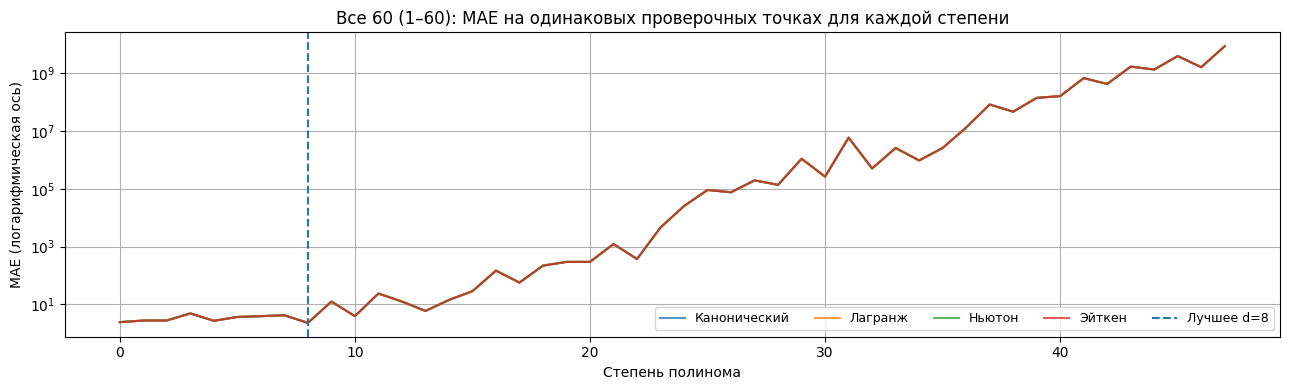

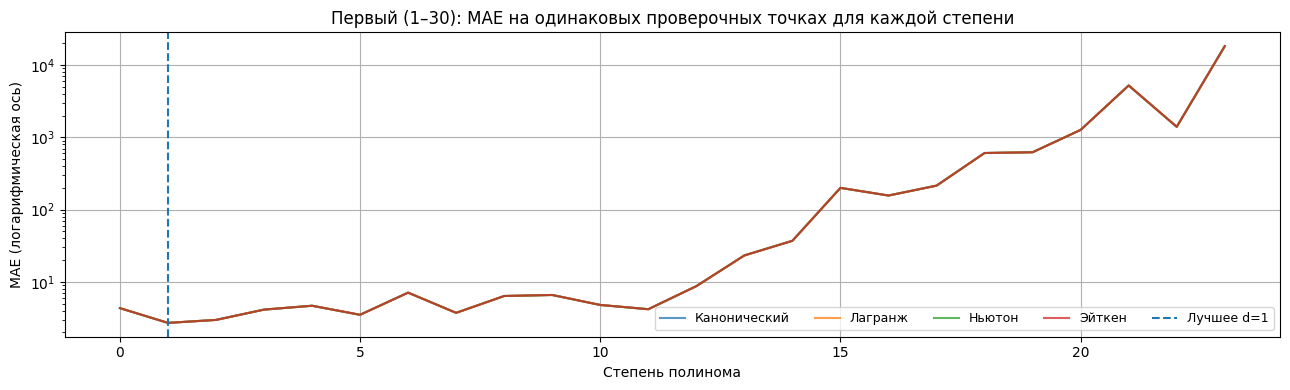

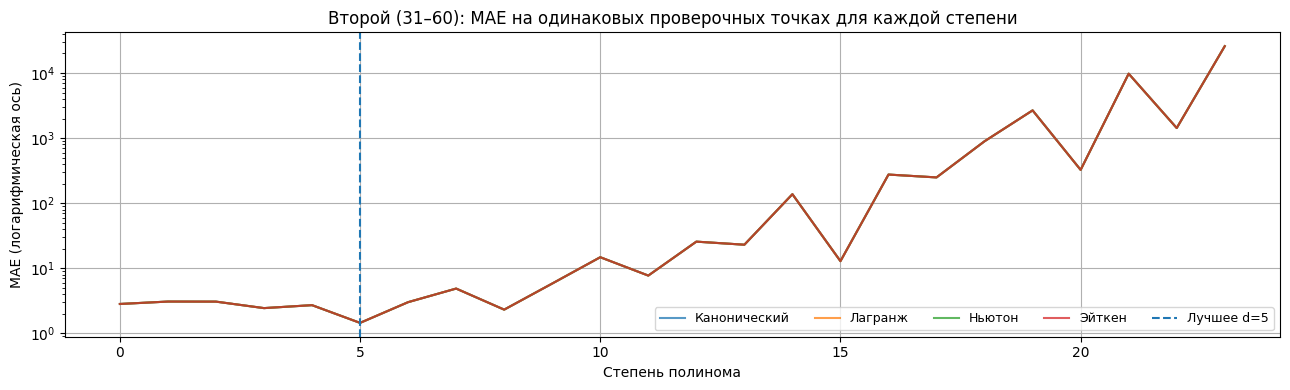

In [7]:
for name, item in SCAN.items():
    fig, ax = plt.subplots(figsize=(13,4))
    for method in METHODS:
        part=item['table']
        s=part[(part['Метод']==method)&(part['Проверка независимая'])].sort_values('Степень')
        ax.plot(s['Степень'], np.maximum(s['MAE проверка'], 1e-12), alpha=.75, label=method)
    b=BEST[(name,'Канонический')]
    ax.axvline(b,ls='--',linewidth=1.5,label=f'Лучшее d={b}')
    ax.set_title(f'{name}: MAE на одинаковых проверочных точках для каждой степени')
    ax.set_xlabel('Степень полинома'); ax.set_ylabel('MAE (логарифмическая ось)')
    ax.set_yscale('log');ax.legend(ncol=5,fontsize=9)
    plt.tight_layout(); plt.show()

## 6. Графики **четырёх методов** при лучшей степени

Точки красного цвета — независимые проверочные наблюдения; чёрные точки — узлы полинома. Видно, насколько близко проходила бы восстановленная кривая к скрытым данным.

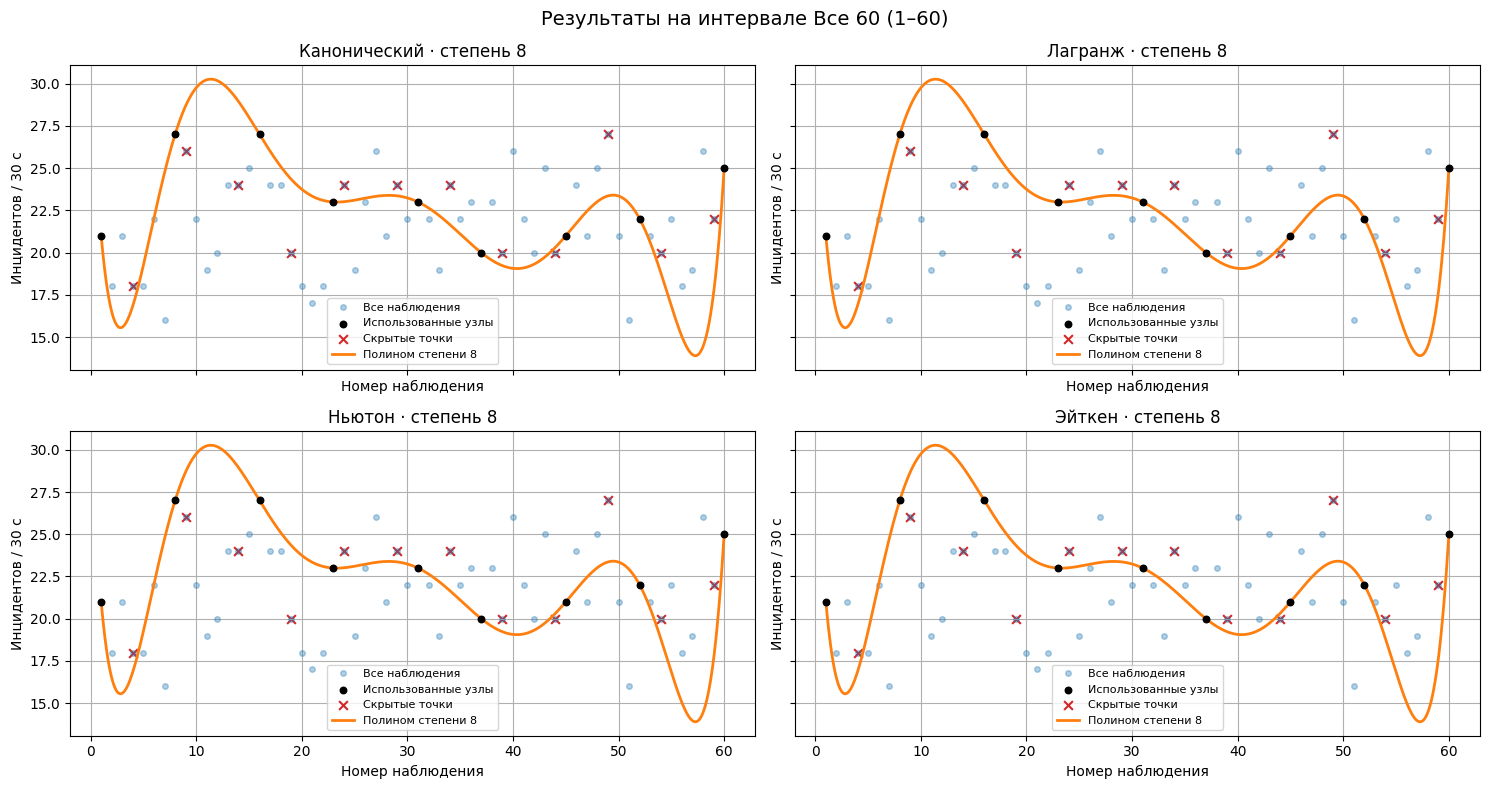

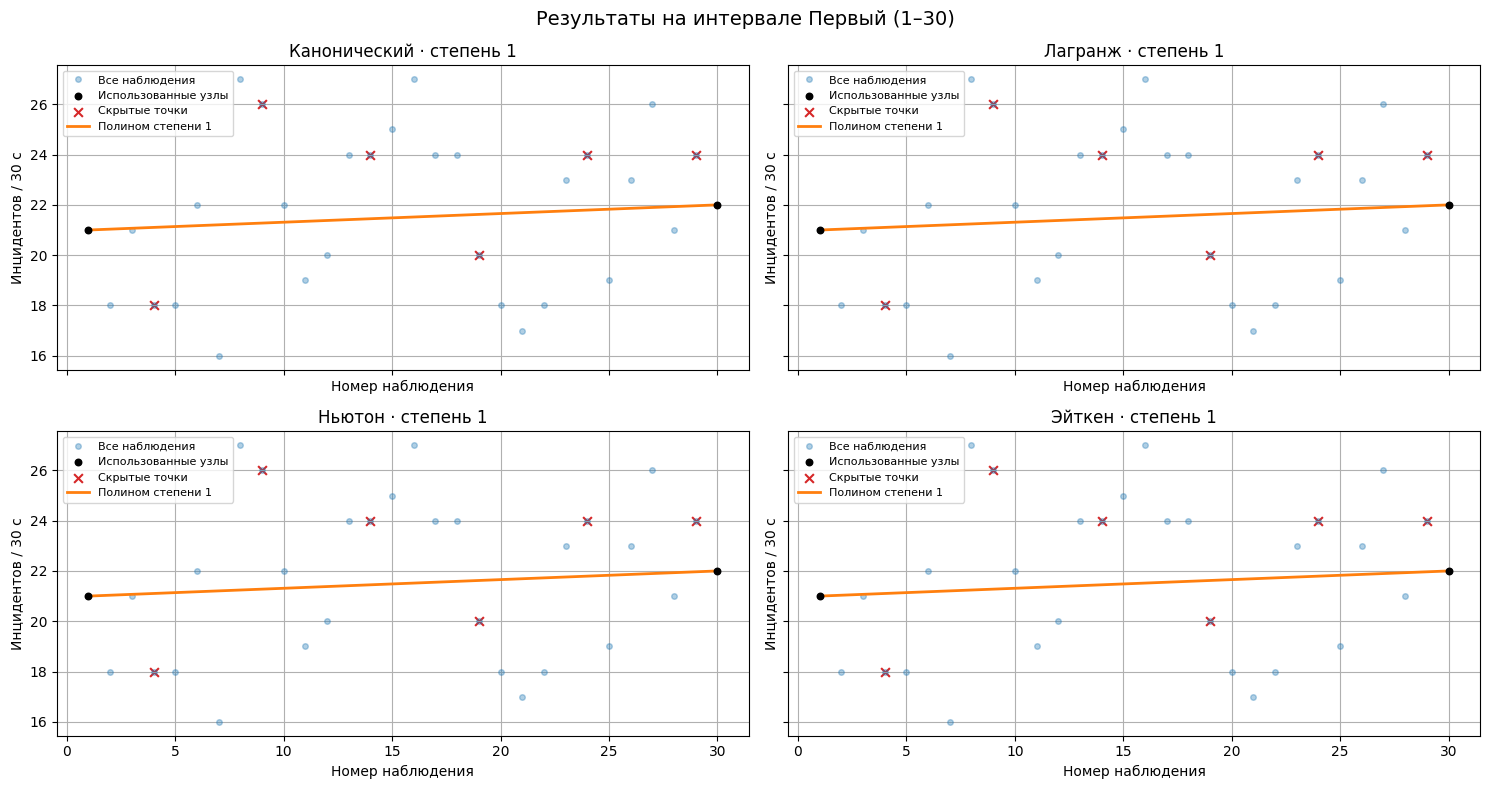

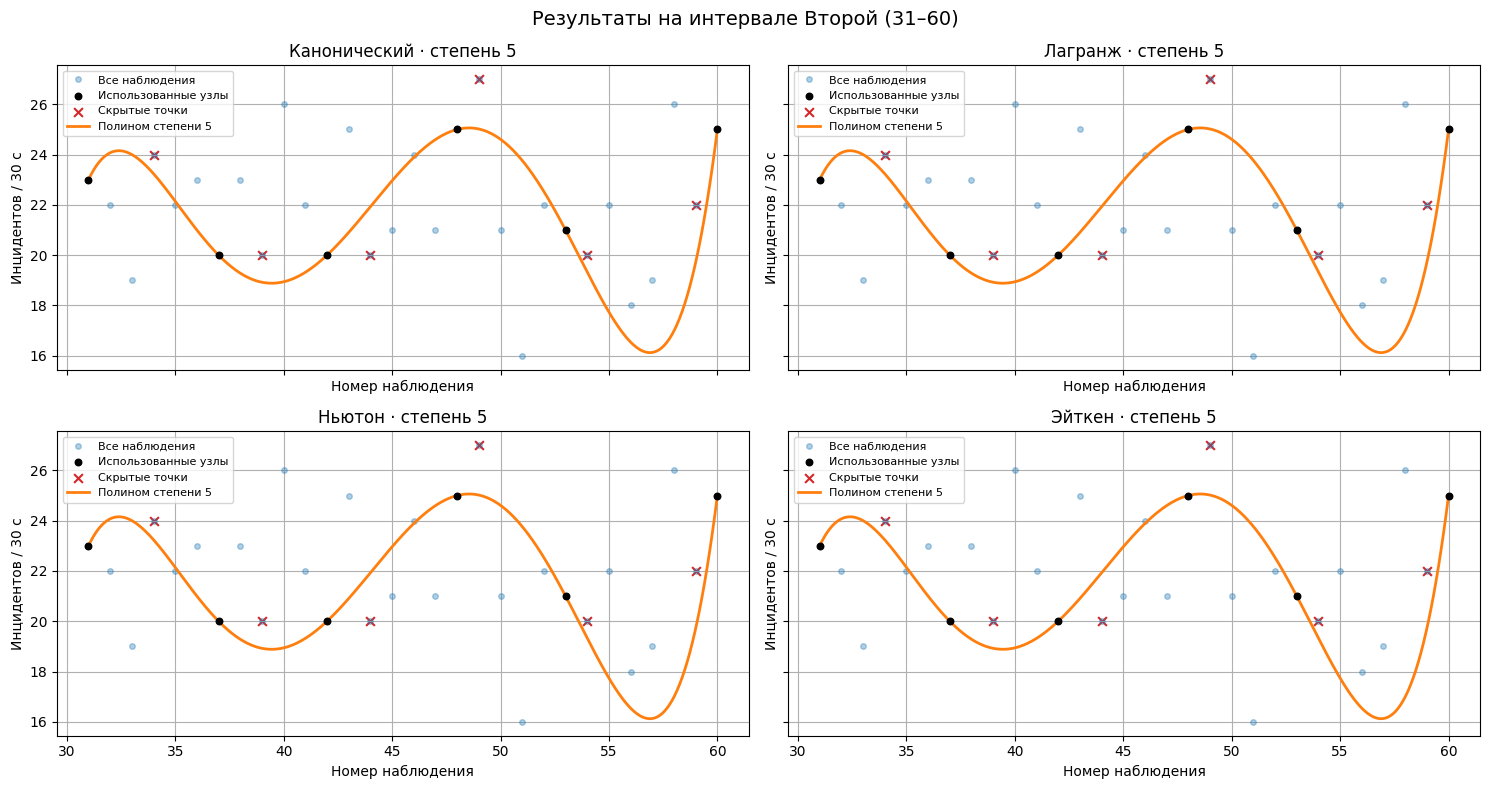

In [8]:
for name, (tx, yy) in INTERVALS.items():
    fig, axes=plt.subplots(2,2,figsize=(15,8),sharex=True,sharey=True)
    for ax,method in zip(axes.flat,METHODS):
        degree=BEST[(name,method)]
        p,nx,ny=MODELS[(name,degree)]
        dense=np.linspace(tx[0],tx[-1],500)
        hat=evaluate(p,dense,method)
        ax.plot(tx,yy,'o',alpha=.35,ms=4,label='Все наблюдения')
        ax.scatter(nx,ny,s=22,color='black',label='Использованные узлы',zorder=4)
        ax.scatter(SCAN[name]['test_x'],SCAN[name]['test_y'],marker='x',s=40,color='tab:red',label='Скрытые точки')
        ax.plot(dense,hat,lw=2,label=f'Полином степени {degree}')
        ax.set_title(method + f' · степень {degree}')
        ax.set_xlabel('Номер наблюдения');ax.set_ylabel('Инцидентов / 30 с')
        ax.legend(fontsize=8)
    fig.suptitle(f'Результаты на интервале {name}',fontsize=14)
    plt.tight_layout();plt.show()

## 7. Просмотр **любой** степени и метода через ползунок

Выберите интервал, метод и степень. Это позволяет в Colab просмотреть **каждый полином, вплоть до степени 59**, не перегружая документ сотнями графиков. Можно переключать обычную шкалу (огромные всплески будут видны) и ограниченную вертикальную шкалу (видны исходные узлы). Ограничение оси — только способ показа, ошибка всегда считается **без обрезки**.

Для Google Colab управление виджетами автоматически включается, если поддерживается средой.

Вы можете вызвать interactive_plot(interval="Все 60 (1–60)", method="Ньютон", degree=10)


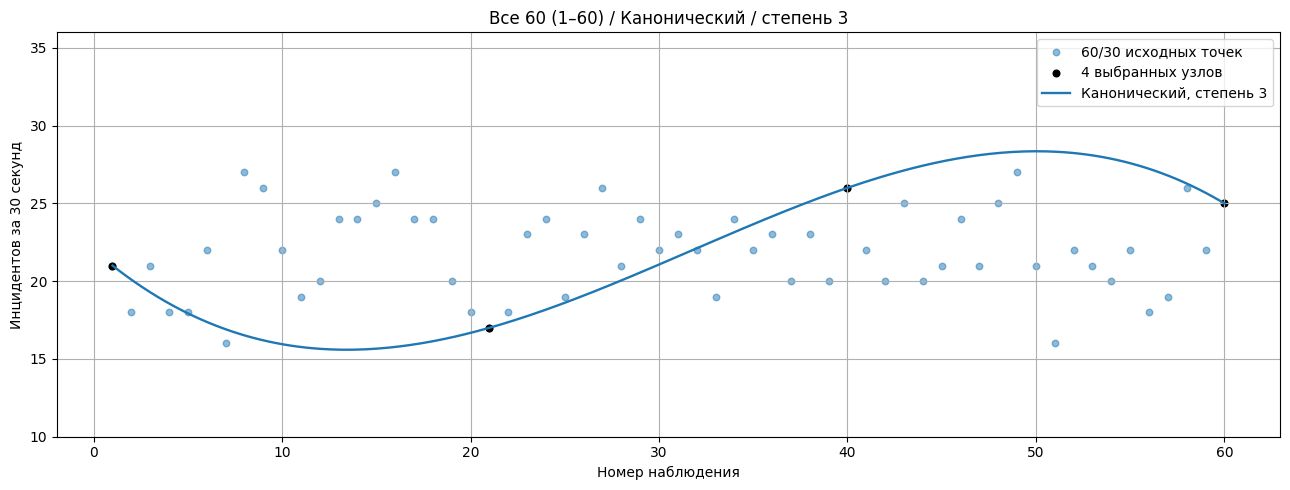

MAE на скрытых точках: 4.8659; MAPE: 21.84%


In [9]:
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

def interactive_plot(interval='Все 60 (1–60)', method='Канонический', degree=3, show_full_scale=False):
    tx,yy=INTERVALS[interval]
    degree=min(degree, len(tx)-1)
    p,nx,ny=MODELS[(interval,degree)]
    dense=np.linspace(tx[0],tx[-1],300)
    hat=evaluate(p,dense,method)
    fig,ax=plt.subplots(figsize=(13,5))
    ax.scatter(tx,yy,s=22,label='60/30 исходных точек',alpha=.5)
    ax.scatter(nx,ny,s=23,color='black',label=f'{degree+1} выбранных узлов')
    ax.plot(dense,hat,lw=1.7,label=f'{method}, степень {degree}')
    if not show_full_scale:
        ax.set_ylim(10,36)
        if np.max(abs(hat))>100:
            print('ВНИМАНИЕ: по вертикали отображается только [10;36]. Полином выходит за границы; ошибки без ограничений.')
    else:
        ax.set_yscale('symlog',linthresh=30)
    ax.set_title(f'{interval} / {method} / степень {degree}')
    ax.set_xlabel('Номер наблюдения');ax.set_ylabel('Инцидентов за 30 секунд')
    ax.legend();plt.tight_layout();plt.show()
    s=SCAN[interval]['table']
    v=s[(s['Метод']==method)&(s['Степень']==degree)].iloc[0]
    if v['Проверка независимая']:
        print(f"MAE на скрытых точках: {v['MAE проверка']:.4f}; MAPE: {v['MAPE проверка, %']:.2f}%")
    else:
        print('Независимая проверка недоступна: степень слишком высокая для текущего набора обучающих узлов.')

if HAS_WIDGETS:
    interact(interactive_plot,
         interval=Dropdown(options=list(INTERVALS),value='Все 60 (1–60)',description='Интервал'),
         method=Dropdown(options=METHODS,value='Канонический',description='Метод'),
         degree=IntSlider(value=3,min=0,max=59,step=1,continuous_update=False,description='Степень'),
         show_full_scale=Checkbox(value=False,description='Полная шкала (symlog)'));
else:
    print('Вы можете вызвать interactive_plot(interval="Все 60 (1–60)", method="Ньютон", degree=10)')
    interactive_plot(interval='Все 60 (1–60)', method='Канонический', degree=3)

## 8. Коэффициенты полиномов и вывод функций

Для любой степени и любого интервала доступны канонические коэффициенты `a₀..aₙ` и разделённые разности Ньютона `c₀..cₙ`. Для Лагранжа и Эйткена коэффициенты того же **единственного полинома** в канонической форме совпадают. Выражение корректно задаётся **в нормированной переменной** `u=(t−центр)/масштаб`. Для высокой степени вывод 60 коэффициентов может быть объёмным, поэтому ниже отображается полный набор коэффициентов **выбранной** степени; для степени 59 нужно вызвать `show_coeffs` с `degree=59`.

In [10]:
def show_coeffs(interval='Все 60 (1–60)', degree=None):
    if degree is None: degree=BEST[(interval,'Канонический')]
    p,_,_=MODELS[(interval,degree)]
    print(f'Интервал: {interval}, степень: {degree}')
    print(f"u = (t - {mp.nstr(p['center'],9)}) / {mp.nstr(p['scale'],9)}")
    print(f'КАНОНИЧЕСКАЯ ФУНКЦИЯ: P(u) = Σ a_k * u^k, k=0..{degree}')
    print('НЬЮТОН: P(u) = c0 + c1*(u-u0) + c2*(u-u0)*(u-u1) + ...')
    display(coeff_table(p))
    return p

for name in INTERVALS:
    show_coeffs(name)

# Раскомментируйте для ВСЕХ 60 коэффициентов полинома 59 степени:
# show_coeffs('Все 60 (1–60)', degree=59)

Интервал: Все 60 (1–60), степень: 8
u = (t - 30.5) / 29.5
КАНОНИЧЕСКАЯ ФУНКЦИЯ: P(u) = Σ a_k * u^k, k=0..8
НЬЮТОН: P(u) = c0 + c1*(u-u0) + c2*(u-u0)*(u-u1) + ...


,Степень u,Канонический a_k,Ньютон: разделённая разность c_k
0,0,23.13389965928,21.0
1,1,-7.05745732423,25.28571428571
2,2,-49.89882708689,-49.72857142857
3,3,4.556921716895,22.22716450216
4,4,372.26475109,61.7689680187
5,5,-4.752856605841,-196.7205160232
6,6,-720.7693856377,327.2556760852
7,7,9.253392213176,-409.2671644388
8,8,398.2695619753,398.2695619753


Интервал: Первый (1–30), степень: 1
u = (t - 15.5) / 14.5
КАНОНИЧЕСКАЯ ФУНКЦИЯ: P(u) = Σ a_k * u^k, k=0..1
НЬЮТОН: P(u) = c0 + c1*(u-u0) + c2*(u-u0)*(u-u1) + ...


,Степень u,Канонический a_k,Ньютон: разделённая разность c_k
0,0,21.5,21.0
1,1,0.5,0.5


Интервал: Второй (31–60), степень: 5
u = (t - 45.5) / 14.5
КАНОНИЧЕСКАЯ ФУНКЦИЯ: P(u) = Σ a_k * u^k, k=0..5
НЬЮТОН: P(u) = c0 + c1*(u-u0) + c2*(u-u0)*(u-u1) + ...


,Степень u,Канонический a_k,Ньютон: разделённая разность c_k
0,0,23.44286651252,23.0
1,1,13.50340369137,-7.25
2,2,-17.05040074122,9.556818181818
3,3,-55.8717175098,5.43426916221
4,4,17.6075342287,-31.74261597847
5,5,43.36831381842,43.36831381842


## 9. Дополнительно: истинная интерполяция или аппроксимация?

Полином, проходящий через все 60 узлов, имеет степень **59**. Если требовать меньшую степень, но **по-прежнему учитывать все 60 наблюдений при построении**, это будет **полиномиальная аппроксимация** (например, метод наименьших квадратов), а не интерполяция. В методичке используются *интерполяционные* формулы, поэтому основной эксперимент выше применяет ровно `d+1` узлов.

Ниже — **дополнительное, необязательное** сравнение с аппроксимацией МНК, когда коэффициенты оцениваются по всем обучающим точкам. Подбор степени по скрытым точкам ограничен степенью 0..(число обучающих точек−1), чтобы избежать использования будущих данных. Это сравнение показывает практическое отличие интерполяции и сглаживания шумных SSH-данных.

МНК: Все 60 (1–60), лучшая степень 3, MAE=2.3259, MAPE=10.15%


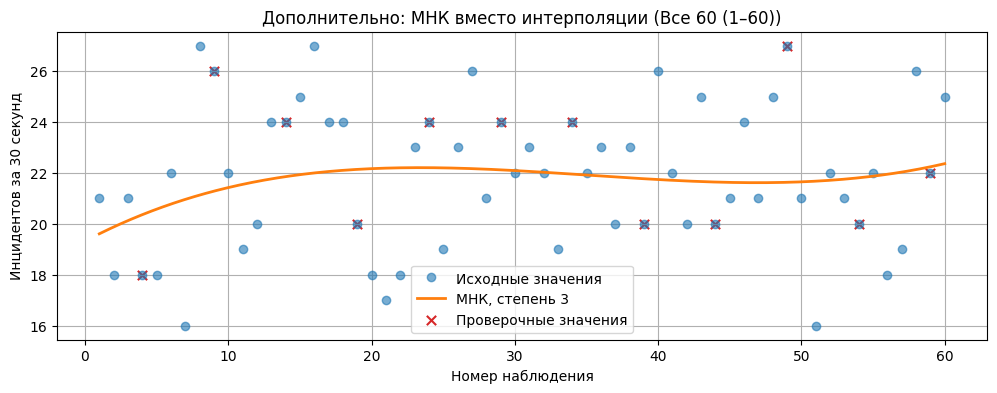

МНК: Первый (1–30), лучшая степень 11, MAE=1.6554, MAPE=7.09%


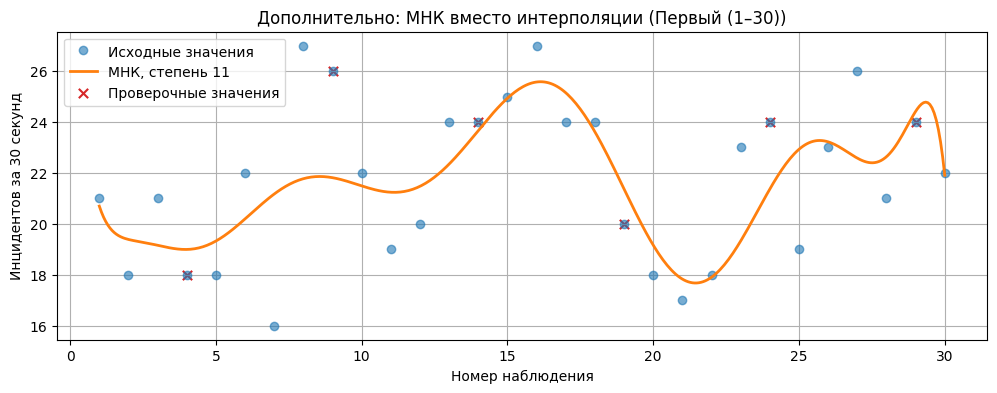

МНК: Второй (31–60), лучшая степень 2, MAE=2.1189, MAPE=9.20%


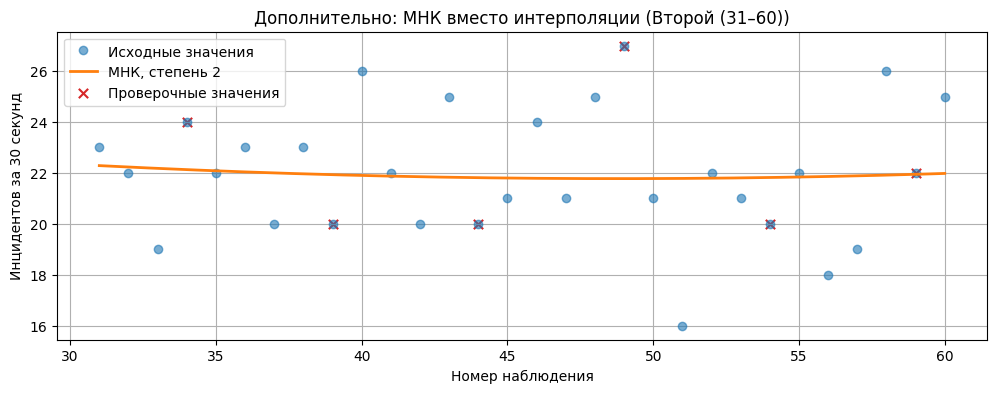

In [11]:
# Численно устойчивый МНК: многочлены Чебышёва, переобозначаемые в стандартный полином.
from numpy.polynomial import Chebyshev
ls_rows=[]; ls_models={}
for name,item in SCAN.items():
    for degree in range(item['max_valid_degree']+1):
        xtr,ytr=item['train_x'],item['train_y']
        xt,yt=item['test_x'],item['test_y']
        mod=Chebyshev.fit(xtr,ytr,deg=degree,domain=[xtr.min(),xtr.max()])
        pred=mod(xt)
        ls_models[(name,degree)]=mod
        ls_rows.append({'Интервал':name,'Степень':degree,**calc_metrics(yt,pred)})
ls_results=pd.DataFrame(ls_rows)
for name in INTERVALS:
    z=ls_results[ls_results['Интервал']==name].sort_values(['MAE','Степень']).iloc[0]
    degree=int(z['Степень'])
    print(f'МНК: {name}, лучшая степень {degree}, MAE={z["MAE"]:.4f}, MAPE={z["MAPE"]:.2f}%')
    x,y=INTERVALS[name]
    dense=np.linspace(x[0],x[-1],400)
    model=ls_models[(name,degree)]
    fig,ax=plt.subplots(figsize=(12,4))
    ax.plot(x,y,'o',alpha=.6,label='Исходные значения')
    ax.plot(dense,model(dense),label=f'МНК, степень {degree}',lw=2)
    ax.scatter(SCAN[name]['test_x'],SCAN[name]['test_y'],color='tab:red',marker='x',label='Проверочные значения',s=45)
    ax.set_title(f'Дополнительно: МНК вместо интерполяции ({name})')
    ax.set_xlabel('Номер наблюдения');ax.set_ylabel('Инцидентов за 30 секунд')
    ax.legend();plt.show()

## 10. Итоговые рекомендации для отчёта

1. По **60 точкам** возможен однозначный интерполяционный полином степени **59**, но не уникальный полином степени 60.
2. Все четыре метода получаются математически эквивалентными — выбор формы вычисления не заменяет выбор степени и узлов.
3. **Точная подгонка узлов не означает качественного прогноза**: высокие степени способны сильно осциллировать между ними (эффект Рунге и переобучение).
4. Обоснованная степень определяется по ошибкам на **скрытых точках**, не использованных при построении. На двух временных интервалах результаты могут отличаться.
5. В разделе с графиками и таблицами можно показать полиномы **высокой, средней и выбранной степени**, а в приложении сослаться на полный автоматизированный перебор всех степеней.

**Важно:** прогнозирование следующих, будущих временных интервалов — это *экстраполяция*, и она может оказаться существенно хуже даже при хорошей интерполяции внутри наблюдаемого диапазона.